# Лабораторная работа №3. Оптимизация гиперпараметров

**Задача:** классификация выживаемости пассажиров Titanic из лабораторной №2.
**Модель:** `DecisionTreeClassifier`. **Метрика:** F1 для `Survived=1` (больше — лучше).

Задача работы — сравнить стратегии поиска при одинаковом бюджете, исследовать сложность
дерева и устойчивость качества. Baseline — **исходное неограниченное дерево `dt_full`**
из раздела 5.1 [лабораторной №2](../classification/lab02_titanic.ipynb), а не DummyClassifier.
В старом ноутбуке для него сохранены train F1 = 0.983 и test F1 = 0.734 (округлённо).
Ниже baseline заново оценивается на CV до поиска, а его test — вместе с финальными моделями.

### Протокол, зафиксированный до запуска

1. Сохраняем признаки и стратифицированное разбиение 80/20 с `random_state=42` из №2.
2. Весь обучаемый препроцессинг находится внутри `Pipeline`; каждый fold обучает его заново.
3. Используем одни и те же 5 стратифицированных folds для baseline, обоих поисков и кривых.
4. Проверяем по 96 кандидатов в каждой стратегии; основная метрика и пространства заданы заранее.
5. Победитель — максимальный средний CV F1 среди baseline и победителей двух поисков.
   При точном равенстве сохраняем порядок Baseline → Grid Search → Random Search.
6. Диагностические кривые поясняют поведение дерева и не расширяют поиск.
   После фиксации победителя обучаем три модели на всём train и один раз оцениваем их на test.

**Ограничение:** этот test уже использовался в №2, поэтому он не является новым, ранее
невиданным контрольным набором. В №3 параметры, алгоритм выбора и диапазоны не меняются
по результатам test. Для независимого подтверждения после всей серии лабораторных нужны новые данные.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, RandomizedSearchCV, ParameterGrid, validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
N_JOBS = 1  # одинаковый режим; для маленьких деревьев нет затрат на запуск процессов
SCORING = make_scorer(f1_score, pos_label=1, zero_division=0)
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'classification/data/Titanic-Dataset.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Запустите ноутбук из репозитория ml_course_mai')
OUT = ROOT / 'hyperparameters/results'
OUT.mkdir(parents=True, exist_ok=True)
DATA_PATH = ROOT / 'classification/data/Titanic-Dataset.csv'
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__}
print(VERSIONS)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
pd.set_option('display.max_columns', 20)

{'python': '3.14.3', 'numpy': '2.4.4', 'pandas': '3.1.0', 'scikit-learn': '1.9.1'}


## 1. Данные и подготовка признаков

Используем локальный CSV (891 пассажир), целевой признак — `Survived`.
F1 = 2TP / (2TP + FP + FN) учитывает и ложные положительные, и пропущенные положительные ответы.
Accuracy недостаточна: большинство пассажиров не выжило. Порог классификации не подбираем,
везде используем стандартный `predict` дерева.

Построчные признаки полностью повторяют №2: титул, размер семьи, одиночное путешествие,
наличие каюты. Они не оценивают статистики по выборке. Идентификаторы исключаем.
Медианы, моды и категории кодировщика оцениваем только внутри обучающих folds.
Масштабирование дереву не требуется: оно сравнивает отдельный признак с порогом.

In [2]:
df = pd.read_csv(DATA_PATH)
TITLE_MAP = {'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'}
MAIN_TITLES = ['Mr', 'Mrs', 'Miss', 'Master']

def make_features(data):
    d = data.copy()
    title = d['Name'].str.extract(r',\s*([^\.]+)\.')[0].str.strip().replace(TITLE_MAP)
    d['Title'] = title.where(title.isin(MAIN_TITLES), 'Rare')
    d['FamilySize'] = d['SibSp'] + d['Parch'] + 1
    d['IsAlone'] = (d['FamilySize'] == 1).astype(int)
    d['HasCabin'] = d['Cabin'].notna().astype(int)
    return d.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

X = make_features(df.drop(columns='Survived'))
y = df['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_test.index)
assert 'Survived' not in X.columns
assert len(X_train) == 712 and len(X_test) == 179
print(f'Train: {len(X_train)}, test отложен: {len(X_test)}')
print('Баланс классов только на train:')
display(y_train.value_counts().rename('count').to_frame())

NUM_FEATURES = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin']
CAT_FEATURES = ['Sex', 'Embarked', 'Title']
preprocessor = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True))]), NUM_FEATURES),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CAT_FEATURES),
], verbose_feature_names_out=False)
baseline = Pipeline([('prep', preprocessor),
                     ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))])
display(pd.Series(baseline.named_steps['model'].get_params(), name='Baseline parameters').to_frame())

Train: 712, test отложен: 179
Баланс классов только на train:


,count
Survived,
0,439
1,273


,Baseline parameters
ccp_alpha,0.0
class_weight,None
criterion,gini
max_depth,None
max_features,None
max_leaf_nodes,None
min_impurity_decrease,0.0
min_samples_leaf,1
min_samples_split,2
min_weight_fraction_leaf,0.0


## 2. Кросс-валидация и исходное качество

**Зачем нужна CV?** Она несколько раз проверяет модель на объектах, не участвовавших
в соответствующем обучении. Среднее меньше зависит от одного удачного разбиения,
а отдельные folds показывают разброс качества.

**Почему 5 folds?** Из 712 обучающих пассажиров примерно 569–570 используются для
обучения и 142–143 для валидации; в каждом валидационном fold около 54–55 выживших.
Стратификация сохраняет доли классов. Это компромисс между объёмом обучения,
устойчивостью оценки F1 и затратами: на кандидата требуется 5 обучений.
При 10 folds валидационные части были бы меньше, а стоимость — примерно вдвое выше.

**Почему недостаточно одного train/test?** Если по нему выбирать параметры, test становится
валидационной выборкой, и независимой проверки уже нет. Даже отдельное единственное
train/validation-разбиение может случайно предпочесть нестабильную конфигурацию.

**Что будет при многократном выборе по test?** Мы косвенно подгоним решение под шум
именно этих объектов, получим оптимистичную оценку и утратим честную проверку обобщения.
Одинаковые folds также делают сравнение кандидатов парным: трудность разбиений совпадает.

In [3]:
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CV = list(splitter.split(X_train, y_train))
fold_sizes = []
for i, (tr, va) in enumerate(CV, 1):
    assert set(tr).isdisjoint(va)
    fold_sizes.append({'fold': i, 'train_n': len(tr), 'validation_n': len(va),
                       'positive_validation_n': int(y_train.iloc[va].sum())})
display(pd.DataFrame(fold_sizes))
baseline_cv = cross_validate(baseline, X_train, y_train, cv=CV, scoring=SCORING,
                            return_train_score=True, n_jobs=N_JOBS, error_score='raise')
baseline_scores = baseline_cv['test_score']  # имя sklearn: здесь test_score означает validation fold!
print(f'Baseline CV F1: {baseline_scores.mean():.4f} ± {baseline_scores.std(ddof=0):.4f}')
print(f'Средний train F1 внутри folds: {baseline_cv["train_score"].mean():.4f}')
print('F1 отдельных folds:', np.round(baseline_scores, 4))

,fold,train_n,validation_n,positive_validation_n
0,1,569,143,55
1,2,569,143,55
2,3,570,142,55
3,4,570,142,54
4,5,570,142,54


Baseline CV F1: 0.7262 ± 0.0279
Средний train F1 внутри folds: 0.9852
F1 отдельных folds: [0.7706 0.7387 0.6916 0.7027 0.7273]


## 3. Три гиперпараметра и пространства поиска

| Параметр | Смысл | Grid Search | Random Search | Ожидаемое влияние |
|---|---|---|---|---|
| `max_depth` | Максимальная длина пути от корня до листа | 1, 3, 5, 8, 12, None | целые 1…12 и None | Малая глубина ограничивает взаимодействия и может недообучать; большая повышает способность запоминать шум |
| `min_samples_leaf` | Минимальное число обучающих объектов в листе | 1, 3, 10, 20 | целые 1…20 | Рост сглаживает решение и уменьшает вариативность; слишком большие листья теряют локальные закономерности |
| `ccp_alpha` | Сила минимально-стоимостной обрезки: штраф за число листьев в критерии impurity + alpha × leaves | 0, 0.001, 0.005, 0.02 | 41 равномерное значение 0…0.02 с шагом 0.0005 | При 0 обрезки нет; рост удаляет слабые ветви, но чрезмерная обрезка приводит к недообучению |

`None` снимает ограничение глубины. Для 712 объектов глубины до 12 уже допускают сложные
деревья, а лист из 20 объектов соответствует примерно 3.5% обучающего fold. Диапазон alpha
включает отсутствие обрезки и заметную регуляризацию относительно impurity Джини порядка 0…0.5.
Параметры взаимодействуют: уже мелкое дерево может почти не изменяться от обрезки.
Остальные параметры (`criterion='gini'`, `splitter='best'`, `min_samples_split=2` и др.)
остаются исходными; не расширяем пространство ради числа комбинаций.

Grid: 6 × 4 × 4 = **96 кандидатов**. Random: **96 разных случайных комбинаций** из
13 × 20 × 41 = **10 660**. Все распределения заданы списками, поэтому выбор происходит
без возвращения. Области параметров одинаковы, но случайный поиск исследует более плотную сетку.
Это сравнение двух практических стратегий при одинаковом числе обучений, а не изоляция
только эффекта порядка перебора. Если случайно перебрать все те же 96 точек Grid, результаты совпадут.

In [4]:
param_grid = {
    'model__max_depth': [1, 3, 5, 8, 12, None],
    'model__min_samples_leaf': [1, 3, 10, 20],
    'model__ccp_alpha': [0.0, 0.001, 0.005, 0.02],
}
param_distributions = {
    'model__max_depth': list(range(1, 13)) + [None],
    'model__min_samples_leaf': list(range(1, 21)),
    'model__ccp_alpha': np.linspace(0.0, 0.02, 41).tolist(),
}
BUDGET = len(ParameterGrid(param_grid))
print('Grid candidates:', BUDGET)
print('Random candidates / space:', BUDGET, '/', len(ParameterGrid(param_distributions)))
common = dict(estimator=baseline, scoring=SCORING, cv=CV, n_jobs=N_JOBS,
              refit=False, return_train_score=True, error_score='raise')
grid = GridSearchCV(param_grid=param_grid, **common)
random_search = RandomizedSearchCV(param_distributions=param_distributions,
                                  n_iter=BUDGET, random_state=RANDOM_STATE, **common)

Grid candidates: 96
Random candidates / space: 96 / 10660


## 4. Grid Search и Random Search

Измеряем реальное время `fit` с `perf_counter`, включая CV и расчёт метрик, **без финального
refit** (`refit=False` у обеих стратегий). Каждая выполняет 96 × 5 = **480 обучений**.
Baseline и диагностические кривые учитываются отдельно. Время одного запуска зависит от
нагрузки компьютера и сложности выбранных деревьев: одинаковое число обучений не гарантирует
точно одинаковое время. Поиски последовательные, `n_jobs=1`, кеширование отключено.

In [5]:
searches = {'Grid Search': grid, 'Random Search': random_search}
search_times = {}
search_rows = []
for name, search in searches.items():
    started = perf_counter()
    search.fit(X_train, y_train)
    search_times[name] = perf_counter() - started
    candidates = search.cv_results_['params']
    assert len(candidates) == BUDGET
    assert len({json.dumps(p, sort_keys=True) for p in candidates}) == BUDGET
    search_rows.append({
        'strategy': name, 'candidates': len(candidates), 'CV fits': len(candidates) * len(CV),
        'CV F1': search.best_score_,
        'CV std': search.cv_results_['std_test_score'][search.best_index_],
        'seconds': search_times[name], 'best_params': search.best_params_,
    })
    pd.DataFrame(search.cv_results_).to_csv(
        OUT / ('grid_cv_results.csv' if name == 'Grid Search' else 'random_cv_results.csv'), index=False)
    print(f'{name}: {search_times[name]:.2f} s, CV F1={search.best_score_:.4f}')
    print(search.best_params_)
search_summary = pd.DataFrame(search_rows).set_index('strategy')
display(search_summary)
search_summary.to_csv(OUT / 'search_summary.csv')

Grid Search: 7.04 s, CV F1=0.7619
{'model__ccp_alpha': 0.0, 'model__max_depth': 3, 'model__min_samples_leaf': 1}


Random Search: 7.24 s, CV F1=0.7594
{'model__min_samples_leaf': 3, 'model__max_depth': None, 'model__ccp_alpha': 0.0035}


,candidates,CV fits,CV F1,CV std,seconds,best_params
strategy,,,,,,
Grid Search,96,480,0.761888,0.046919,7.035800,"{'model__ccp_alpha': 0.0, 'model__max_depth': ..."
Random Search,96,480,0.759380,0.030710,7.244165,"{'model__min_samples_leaf': 3, 'model__max_dep..."


## 5. Влияние параметров: train и validation

Меняем **один параметр за раз**, остальные оставляем как у baseline. Это условные срезы,
они не показывают все взаимодействия и могут иметь другой максимум, чем совместный поиск.
Каждая точка — среднее по тем же folds; полоса показывает ±1 стандартное отклонение
валидационного F1 (не доверительный интервал). Train F1 тоже усредняется внутри folds.

Для демонстрации сильной регуляризации диагностические диапазоны листа и alpha шире
поисковых; они заданы заранее и **не участвуют в выборе финальных параметров**.
Недообучение ищем там, где обе оценки низкие; переобучение — там, где train заметно выше CV,
а усложнение не улучшает CV. Сам по себе разрыв не доказывает переобучение.

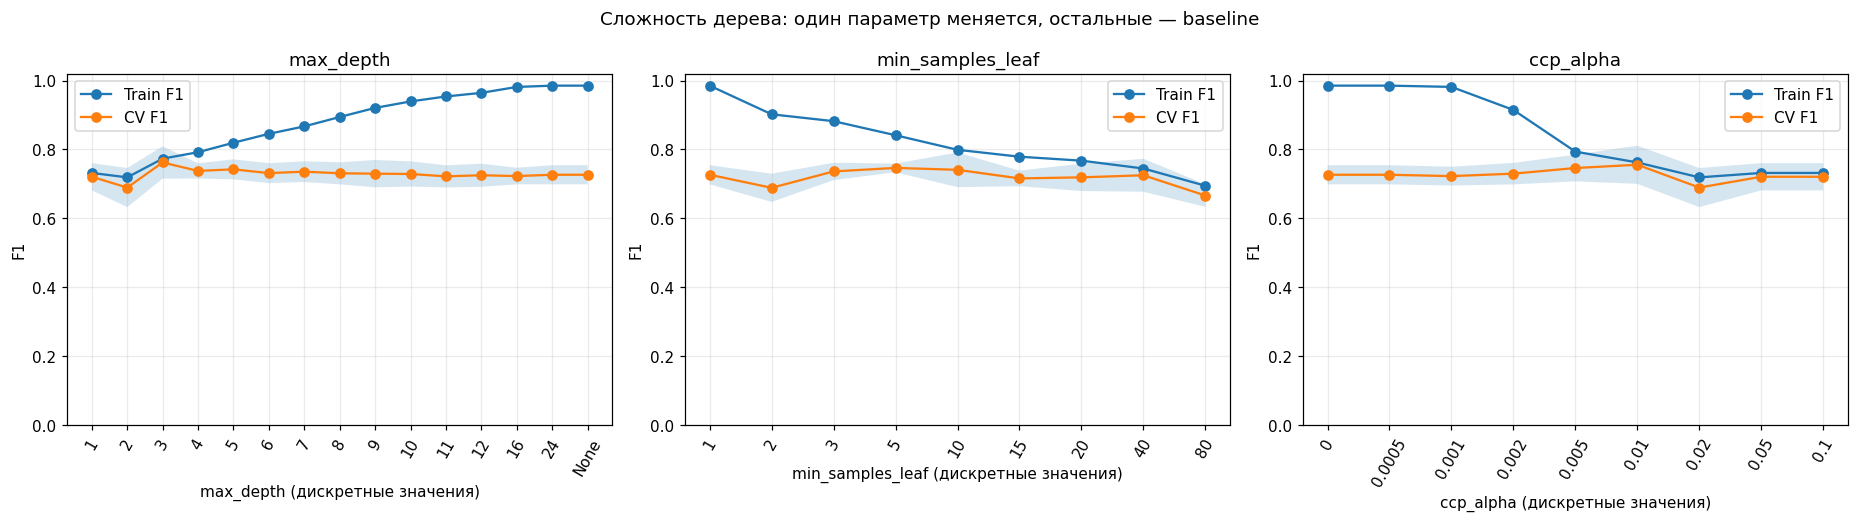

,parameter,value,train_mean,cv_mean,cv_std
0,max_depth,1,0.7314,0.7204,0.0397
1,max_depth,2,0.7186,0.6889,0.0569
2,max_depth,3,0.7730,0.7619,0.0469
3,max_depth,4,0.7917,0.7373,0.0221
4,max_depth,5,0.8192,0.7419,0.0291
5,max_depth,6,0.8451,0.7309,0.0289
6,max_depth,7,0.8667,0.7352,0.0301
7,max_depth,8,0.8940,0.7304,0.0320
8,max_depth,9,0.9205,0.7293,0.0397
9,max_depth,10,0.9392,0.7284,0.0367


Диагностических обучений: 165


In [6]:
curve_ranges = {
    'max_depth': list(range(1, 13)) + [16, 24, None],
    'min_samples_leaf': [1, 2, 3, 5, 10, 15, 20, 40, 80],
    'ccp_alpha': [0.0, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1],
}
curve_rows = []
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (param, values) in zip(axes, curve_ranges.items()):
    train_s, val_s = validation_curve(
        baseline, X_train, y_train, param_name=f'model__{param}', param_range=values,
        cv=CV, scoring=SCORING, n_jobs=N_JOBS, error_score='raise')
    train_mean, val_mean = train_s.mean(axis=1), val_s.mean(axis=1)
    val_std = val_s.std(axis=1, ddof=0)
    positions = np.arange(len(values))
    ax.plot(positions, train_mean, 'o-', label='Train F1')
    ax.plot(positions, val_mean, 'o-', label='CV F1')
    ax.fill_between(positions, val_mean-val_std, val_mean+val_std, alpha=0.18)
    ax.set_xticks(positions, ['None' if v is None else f'{v:g}' for v in values], rotation=60)
    ax.set(xlabel=param + ' (дискретные значения)', ylabel='F1', ylim=(0, 1.02), title=param)
    ax.legend()
    for j, value in enumerate(values):
        curve_rows.append({'parameter': param, 'value': 'None' if value is None else str(value),
                           'train_mean': train_mean[j], 'cv_mean': val_mean[j], 'cv_std': val_std[j]})
fig.suptitle('Сложность дерева: один параметр меняется, остальные — baseline')
fig.tight_layout()
fig.savefig(OUT / 'validation_curves.png', bbox_inches='tight')
plt.show()
curves = pd.DataFrame(curve_rows)
curves.to_csv(OUT / 'validation_curves.csv', index=False)
display(curves.round(4))
print('Диагностических обучений:', sum(map(len, curve_ranges.values())) * len(CV))

In [7]:
curve_notes = []
for param in curve_ranges:
    section = curves[curves['parameter'] == param]
    peak = section.loc[section['cv_mean'].idxmax()]
    start, end = section.iloc[0], section.iloc[-1]
    curve_notes.append(
        f'- **{param}**: лучший условный CV F1 = {peak.cv_mean:.4f} при {peak.value}; '
        f'на левом краю train/CV = {start.train_mean:.4f}/{start.cv_mean:.4f}, '
        f'на правом — {end.train_mean:.4f}/{end.cv_mean:.4f}.')
display(Markdown('\n'.join(curve_notes)))

- **max_depth**: лучший условный CV F1 = 0.7619 при 3; на левом краю train/CV = 0.7314/0.7204, на правом — 0.9852/0.7262.
- **min_samples_leaf**: лучший условный CV F1 = 0.7461 при 5; на левом краю train/CV = 0.9852/0.7262, на правом — 0.6943/0.6657.
- **ccp_alpha**: лучший условный CV F1 = 0.7553 при 0.01; на левом краю train/CV = 0.9852/0.7262, на правом — 0.7314/0.7204.

**Интерпретация.** Глубина 1 даёт очень простое правило: близкие train/CV сами по себе
не означают достаточную выразительность — сравниваем их с максимумом CV при умеренной глубине.
Глубокое неограниченное дерево хорошо запоминает train; если CV при этом хуже, это область
переобучения. Умеренная глубина и/или регуляризация дают разумный компромисс.

Увеличение `min_samples_leaf` запрещает правила для единичных пассажиров; слишком большие
листья сглаживают полезные зависимости. Рост `ccp_alpha` удаляет ветви и меняет дерево
скачками: между порогами обрезки кривая может быть плоской. Сильная обрезка может оставить
только простое правило или корень, что ограничивает качество. На малой выборке не ждём
монотонности F1: дерево оптимизирует impurity, а не сам F1, и изменение одного решения
заметно меняет метрику. Области разумной сложности определяем по CV, а не по test.

## 6. Устойчивость по отдельным folds и фиксация решения

Для каждого победителя берём **его пять оценок**, уже полученных при поиске.
`std(ddof=0)` совпадает с определением `std_test_score` в поиске; также показываем минимум,
максимум и размах. Fold №k у всех моделей один и тот же.

Модели с одинаковым средним могут иметь разный разброс: одна работает ровно, другая
сильно зависит от состава обучающих/валидационных пассажиров, редких групп и шума.
Меньший разброс обычно удобнее, но пять зависимых оценок недостаточны для доказательства
превосходства. Это устойчивость к данным folds, а не ко всем seed и будущим данным.

,Baseline,Grid Search,Random Search
fold,,,
1,0.7706,0.7818,0.7810
2,0.7387,0.7021,0.7193
3,0.6916,0.8350,0.8000
4,0.7027,0.7213,0.7290
5,0.7273,0.7692,0.7677


,mean,std,min,max,range
Baseline,0.7262,0.0279,0.6916,0.7706,0.0791
Grid Search,0.7619,0.0469,0.7021,0.8350,0.1328
Random Search,0.7594,0.0307,0.7193,0.8000,0.0807


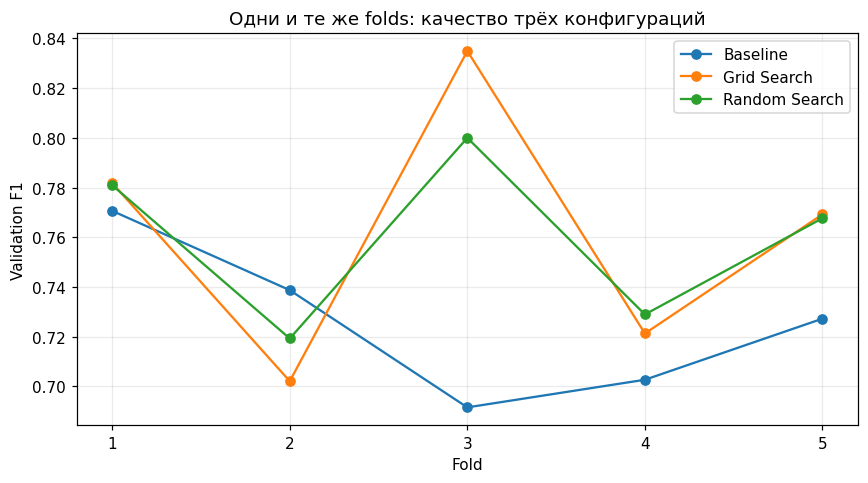

Зафиксирована финальная модель: Grid Search {'model__ccp_alpha': 0.0, 'model__max_depth': 3, 'model__min_samples_leaf': 1}


In [8]:
fold_scores = {'Baseline': baseline_scores}
model_params = {'Baseline': {}}
cv_means = {'Baseline': baseline_scores.mean()}
for name, search in searches.items():
    fold_scores[name] = np.array([search.cv_results_[f'split{i}_test_score'][search.best_index_]
                                 for i in range(len(CV))])
    model_params[name] = search.best_params_
    cv_means[name] = search.best_score_
fold_table = pd.DataFrame(fold_scores, index=pd.Index(range(1, 6), name='fold'))
stability = pd.DataFrame({name: {'mean': scores.mean(), 'std': scores.std(ddof=0),
                                'min': scores.min(), 'max': scores.max(), 'range': np.ptp(scores)}
                          for name, scores in fold_scores.items()}).T
display(fold_table.round(4))
display(stability.round(4))
fold_table.to_csv(OUT / 'fold_scores.csv')
stability.to_csv(OUT / 'stability.csv')
ax = fold_table.plot(marker='o', figsize=(8, 4.5), xticks=range(1, 6))
ax.set(xlabel='Fold', ylabel='Validation F1', title='Одни и те же folds: качество трёх конфигураций')
plt.tight_layout()
plt.savefig(OUT / 'fold_scores.png', bbox_inches='tight')
plt.show()

# Решение фиксируется ДО обучения финальных моделей и ДО любых прогнозов на test.
selected_name = max(cv_means, key=cv_means.get)
selection = {
    'selected_model': selected_name, 'selected_params': model_params[selected_name],
    'selection_rule': 'maximum mean training CV F1; exact ties: Baseline, Grid, Random',
    'seed': RANDOM_STATE, 'folds': 5, 'scoring': 'binary F1, positive=1',
    'versions': VERSIONS, 'dataset_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    'baseline_params': baseline.named_steps['model'].get_params(),
    'grid_space': param_grid, 'random_space': param_distributions,
    'train_indices': X_train.index.tolist(), 'test_indices': X_test.index.tolist(),
    'cv_folds_train_positions': [{'train': tr.tolist(), 'validation': va.tolist()} for tr, va in CV],
    'cv_means': cv_means, 'candidate_params': model_params,
}
(OUT / 'selection_before_test.json').write_text(json.dumps(selection, indent=2, ensure_ascii=False), encoding='utf-8')
print('Зафиксирована финальная модель:', selected_name, model_params[selected_name])

## 7. Финальное обучение и однократная проверка на test

Настройки всех трёх моделей и победитель уже зафиксированы. Обучаем их на 712 пассажирах
train, затем получаем по одному прогнозу на 179 тестовых пассажирах. Не меняем выбор по
этой таблице. CV — среднее на валидационных folds, Test — F1 на общей отложенной выборке.

,CV F1,CV std,Test F1,Train F1,depth,leaves,selected by CV,CV delta vs baseline,Test delta vs baseline
model,,,,,,,,,
Baseline,0.7262,0.0279,0.7338,0.9833,22,157,False,0.0000,0.0000
Grid Search,0.7619,0.0469,0.7692,0.7683,3,8,True,0.0357,0.0354
Random Search,0.7594,0.0307,0.6667,0.7899,6,12,False,0.0332,-0.0671


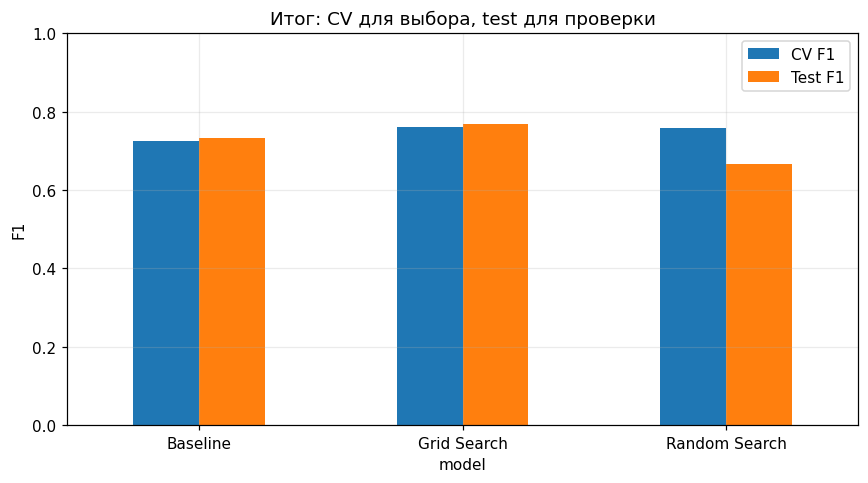

In [9]:
fitted_models = {}
for name, params in model_params.items():
    fitted_models[name] = clone(baseline).set_params(**params).fit(X_train, y_train)
final_model = fitted_models[selected_name]

final_rows = []
test_predictions = pd.DataFrame({'PassengerId': df.loc[X_test.index, 'PassengerId'],
                                 'Survived': y_test})
for name, model in fitted_models.items():
    prediction = model.predict(X_test)  # единственное обращение модели к test
    test_predictions[name] = prediction
    tree = model.named_steps['model']
    final_rows.append({'model': name, 'CV F1': cv_means[name],
                       'CV std': fold_scores[name].std(ddof=0),
                       'Test F1': f1_score(y_test, prediction, zero_division=0),
                       'Train F1': f1_score(y_train, model.predict(X_train), zero_division=0),
                       'depth': tree.get_depth(), 'leaves': tree.get_n_leaves(),
                       'selected by CV': name == selected_name})
comparison = pd.DataFrame(final_rows).set_index('model')
comparison['CV delta vs baseline'] = comparison['CV F1'] - comparison.loc['Baseline', 'CV F1']
comparison['Test delta vs baseline'] = comparison['Test F1'] - comparison.loc['Baseline', 'Test F1']
display(comparison.round(4))
comparison.to_csv(OUT / 'model_comparison.csv')
test_predictions.to_csv(OUT / 'test_predictions.csv', index_label='source_row')
ax = comparison[['CV F1', 'Test F1']].plot.bar(figsize=(8, 4.5), rot=0, ylim=(0, 1))
ax.set(ylabel='F1', title='Итог: CV для выбора, test для проверки')
plt.tight_layout()
plt.savefig(OUT / 'model_comparison.png', bbox_inches='tight')
plt.show()

## 8. Ответы и выводы по фактическому запуску

In [10]:
selected = comparison.loc[selected_name]
grid_row, random_row = comparison.loc['Grid Search'], comparison.loc['Random Search']
delta_cv = selected['CV delta vs baseline']
delta_test = selected['Test delta vs baseline']
direction_matches = np.sign(delta_cv) == np.sign(delta_test)
notes = f"""
**Baseline:** CV F1 = {comparison.loc['Baseline', 'CV F1']:.4f},
test F1 = {comparison.loc['Baseline', 'Test F1']:.4f}.

**Grid Search:** {BUDGET} кандидатов, {BUDGET * len(CV)} CV-обучений,
{search_times['Grid Search']:.2f} с; CV F1 = {grid_row['CV F1']:.4f},
test F1 = {grid_row['Test F1']:.4f}. Параметры: `{grid.best_params_}`.

**Random Search:** {BUDGET} кандидатов, {BUDGET * len(CV)} CV-обучений,
{search_times['Random Search']:.2f} с; CV F1 = {random_row['CV F1']:.4f},
test F1 = {random_row['Test F1']:.4f}. Параметры: `{random_search.best_params_}`.
Разница Random − Grid по CV: {random_row['CV F1'] - grid_row['CV F1']:+.4f};
по test: {random_row['Test F1'] - grid_row['Test F1']:+.4f}.

**Выбранная по CV модель — {selected_name}** (`{model_params[selected_name]}`).
Изменение относительно baseline: **{delta_cv:+.4f} F1 по CV**
({delta_cv * 100:+.2f} процентного пункта шкалы F1),
**{delta_test:+.4f} F1 по test** ({delta_test * 100:+.2f} п. п.).
Направление изменения CV и test {'совпало' if direction_matches else 'не совпало'};
величины изменений не обязаны совпадать. Финальное дерево имеет глубину
{int(selected['depth'])} и {int(selected['leaves'])} листьев.

**Устойчивость:** std F1 baseline = {comparison.loc['Baseline', 'CV std']:.4f},
Grid = {grid_row['CV std']:.4f}, Random = {random_row['CV std']:.4f}.
Для выбранной модели диапазон fold F1 —
{stability.loc[selected_name, 'min']:.4f}…{stability.loc[selected_name, 'max']:.4f}.
Разброс характеризует чувствительность к конкретным разбиениям, а не доверительный интервал.
"""
display(Markdown(notes))
(OUT / 'summary.md').write_text('# Результаты лабораторной №3\n\n' + notes + '\n\n'
                                + '\n'.join(curve_notes), encoding='utf-8')


**Baseline:** CV F1 = 0.7262,
test F1 = 0.7338.

**Grid Search:** 96 кандидатов, 480 CV-обучений,
7.04 с; CV F1 = 0.7619,
test F1 = 0.7692. Параметры: `{'model__ccp_alpha': 0.0, 'model__max_depth': 3, 'model__min_samples_leaf': 1}`.

**Random Search:** 96 кандидатов, 480 CV-обучений,
7.24 с; CV F1 = 0.7594,
test F1 = 0.6667. Параметры: `{'model__min_samples_leaf': 3, 'model__max_depth': None, 'model__ccp_alpha': 0.0035}`.
Разница Random − Grid по CV: -0.0025;
по test: -0.1026.

**Выбранная по CV модель — Grid Search** (`{'model__ccp_alpha': 0.0, 'model__max_depth': 3, 'model__min_samples_leaf': 1}`).
Изменение относительно baseline: **+0.0357 F1 по CV**
(+3.57 процентного пункта шкалы F1),
**+0.0354 F1 по test** (+3.54 п. п.).
Направление изменения CV и test совпало;
величины изменений не обязаны совпадать. Финальное дерево имеет глубину
3 и 8 листьев.

**Устойчивость:** std F1 baseline = 0.0279,
Grid = 0.0469, Random = 0.0307.
Для выбранной модели диапазон fold F1 —
0.7021…0.8350.
Разброс характеризует чувствительность к конкретным разбиениям, а не доверительный интервал.


1498

### Что именно показал этот запуск

У Grid улучшение относительно baseline подтверждается в обеих оценках: **+0.0357 CV F1**
и **+0.0354 Test F1**. У Random Search ситуация иная: **+0.0332 по CV**, но **−0.0671 по test**.
В его финальном дереве 6 уровней и 12 листьев, у Grid — 3 уровня и 8 листьев.
Это пример того, что хороший результат подбора не гарантирует улучшения на другом наборе
пассажиров. Разный состав выборок, чувствительность дерева к данным и оптимизм выбора по CV —
возможные объяснения; по одному test нельзя установить вклад каждой причины.

Разница средних CV у Grid и Random всего **0.0025**, тогда как их std по folds — **0.0469**
и **0.0307**. Grid выигрывает по заранее установленному правилу максимума среднего, но
Random ровнее на этих folds. У baseline std ещё меньше (**0.0279**), однако среднее качество
хуже. Следовательно, низкий разброс не заменяет хорошее среднее, а прирост среднего
не означает прирост устойчивости. Уверенное статистическое превосходство здесь не заявляется.

На диагностических срезах разумная сложность достигается при **глубине 3** (CV 0.7619),
**листе 5** (CV 0.7461) или **alpha=0.01** (CV 0.7553), когда прочие параметры исходные.
Это три отдельных эксперимента: складывать их максимумы в новую комбинацию без CV нельзя.
Неограниченное дерево имеет средний train F1 0.9852 при CV 0.7262 — выраженный разрыв.
Глубина 1 даёт train/CV 0.7314/0.7204 и недообучает относительно глубины 3;
лист 80 снижает обе оценки до 0.6943/0.6657. Обрезка ведёт себя немонотонно по F1:
при alpha=0.02 CV падает, а при 0.05–0.1 возвращается к 0.7204. Это согласуется с тем,
что дерево оптимизирует Джини и меняет структуру скачками, а не непосредственно максимизирует F1.

Эти наблюдения описывают выполненный запуск с зафиксированными версиями и seed.
Они не используются для повторного подбора после просмотра test.


### Почему результаты CV и test могут различаться?

Валидационные и тестовые пассажиры имеют разный состав; test содержит всего 179 объектов,
поэтому несколько ошибок заметно меняют F1. В folds модель обучалась примерно на 570
пассажирах, финальная — на 712. Кроме того, лучший CV score выбран как максимум из 96
кандидатов и имеет оптимизм выбора. Поэтому улучшение CV не гарантирует такого же улучшения
на test, а лидер по test может отличаться. Это не повод менять уже выбранную модель.

### Когда Random Search предпочтительнее Grid Search?

При многих параметрах сетка растёт произведением числа значений и тратит много обучений
на одинаковые значения наиболее важных параметров. Случайный поиск позволяет заранее
ограничить бюджет и покрыть больше их значений; особенно полезен, если влияют лишь несколько
параметров или есть широкие непрерывные диапазоны (например, с логарифмическим распределением).
Он может пропустить узкую хорошую область и зависит от seed. Для трёх параметров и небольшой
осмысленной сетки Grid тоже удобен. Один запуск с seed=42 не доказывает общего превосходства
стратегии; для этого нужны повторения поиска с разными seed и отдельный бюджет.

### Ограничения и честность эксперимента

- CV победителя одновременно использовалась для его выбора, поэтому это оценка выбора,
  а не независимое доказательство качества. Для оценки всей процедуры пригодилась бы nested CV.
- В таблице устойчивости folds пересекаются обучающими частями, поэтому их нельзя считать
  пятью независимыми экспериментами или заключать о значимости по пересечению полос ±std.
- Случайное разбиение пассажиров сохраняет протокол №2, но родственники/попутчики могут
  попасть в разные части; для переноса на новые семьи нужна отдельная проверка по группам.
- Исторический test уже был просмотрен в №2. В этой работе нет дополнительных поисков,
  изменений диапазонов, выбора порога или выбора победителя по test.
- Указанные времена измерены на текущем компьютере; сравнение бюджетов опирается прежде
  всего на одинаковые 96 кандидатов и 480 обучений каждой стратегии.

**Итог:** сохранены исходная модель, оба пространства, полные результаты кандидатов,
время, пять оценок каждого победителя, кривые трёх параметров и финальная проверка.
`results/selection_before_test.json` записывается до вычисления тестовых метрик и содержит
параметры, правило выбора, индексы выборок/folds, версии и хеш исходных данных.